# Beyond: the reconciliations against reference engines that exist today

- **Level:** 4, Beyond the state of the art
- **Prerequisites:** notebooks 03, 05 and 06 of this topic (the embedding, the calibration and the low-default bounds)
- **Reading time:** about 35 minutes

## Objectives

By the end of this notebook you can:

- list the reconciliations of the engine against independent references that exist today for the ratings and calibration cases: five printed papers and the SciPy distributions behind the test statistics;
- read, for each source, how many printed numbers were recomputed, how many agree to the printed digit and the largest gap, from the committed artifacts;
- check the engine's p-values against SciPy on a grid;
- say which gaps the artifacts record and with what explanation, and which reconciliations are not run and therefore not claimed;
- state the claim BS-2 of the product, the evidence behind it and its limits.

## Setup

Install the pinned environment once, in a virtual environment, with the familiar command:

```bash
pip install -r notebooks/requirements.txt
```

or only the packages this notebook uses, with the same exact pins:

```bash
pip install riskvalidation==0.8.1 numpy==2.4.6 scipy==1.18.1 matplotlib==3.11.2
```

`scripts/setup.sh --notebooks` (`scripts/setup.ps1 -Notebooks` on Windows) builds `.venv-notebooks` for you. The next cell imports the packages and prints their versions.

In [1]:
# Import the tools and print the versions they run with, to compare them with notebooks/requirements.txt
import importlib.metadata as md
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import riskvalidation as rv
from riskvalidation import validation
from scipy import stats

for name in ("riskvalidation", "numpy", "scipy", "matplotlib"):
    print(name, md.version(name))

riskvalidation 0.8.1
numpy 2.4.6
scipy 1.18.1
matplotlib 3.11.2


## Data

Four committed files, all produced by the pipeline from papers that are derived-only sources (the artifacts carry the printed numbers and the recomputation, never the papers' own tables of counts):

- `data/derived/C04/published.json`: three papers recomputed beside their prints. Israel, Rosenthal and Wei (2001): nine L1 distances. Schuermann and Hanson (2004), Table 5: the Wald and Agresti-Coull intervals for BB in 2002. Engelmann (2024): the TTC portfolio and four starting portfolios.
- `data/derived/C05/sp-2010.json` and `sp-2011.json`: Tasche (2013), Tables 5 to 9 (`outputs.golden`): the smoothed curve, the implied profile, the forecast curves of four approaches, the p-values, the case 3 PDs and the likelihood ratios.
- `data/derived/C05/ldp-published.json`: Pluto and Tasche (2005), Tables 1 to 14, 204 cells (`outputs.golden.cells`).

The repository's own reconciliation tests (`tests/test_c04_parity.py`, `tests/test_c04_published.py`, `tests/test_c05.py`) run in the product's test suite, not here. The next cell loads the files.

In [2]:
# Load the four artifacts (the notebook sits three folders below the repository root) and print the engine versions
ROOT = Path("../../..").resolve()
DERIVED = ROOT / "data" / "derived"
load = lambda case, name: json.loads((DERIVED / case / name).read_text(encoding="utf-8"))
published, ldp = load("C04", "published.json"), load("C05", "ldp-published.json")
tasche = {2010: load("C05", "sp-2010.json"), 2011: load("C05", "sp-2011.json")}
for label, doc in (("published", published), ("ldp-published", ldp), ("sp-2010", tasche[2010]), ("sp-2011", tasche[2011])):
    print(f"{label:14s} baked by riskvalidation", doc["provenance"]["riskvalidation_version"], "| installed", rv.__version__)

published      baked by riskvalidation 0.4.3 | installed 0.8.1
ldp-published  baked by riskvalidation 0.4.3 | installed 0.8.1
sp-2010        baked by riskvalidation 0.4.3 | installed 0.8.1
sp-2011        baked by riskvalidation 0.4.3 | installed 0.8.1


## Method

### Step 1: what is reconciled, source by source

A reconciliation recomputes a published number with the engine and puts the two side by side. Each artifact records, for every printed number, the print, the recomputation and the gap. The next cell tallies them by source: the number of printed numbers compared, how many the engine reproduces to the printed digit, and the largest gap in the unit of the print. A gap is zero when the recomputed value, rounded to the printed precision, equals the print; the rules for each table (for instance "within half a unit of the last printed digit") are the artifacts' own and are listed in the notes of this notebook's results.

In [3]:
# Tally the printed numbers recomputed by source: how many, how many agree to the printed digit, and the largest gap
rows = []                                               # (source, numbers compared, agree, largest gap, unit)
out_pub = published["outputs"]

irw = out_pub["irw"]["rows"]
rows.append(("Israel et al. (2001), L1 distances", len(irw), sum(r["agrees"] for r in irw), max(abs(r["printed"] - r["recomputed"]) for r in irw), "L1 distance"))
sr = out_pub["sr190"]["rows"]
cells = [(p, r_) for row in sr for p, r_ in zip(row["printed"], row["recomputed"])]
rows.append(("Schuermann and Hanson (2004), Table 5", len(cells), sum(row["agrees"] for row in sr) * 3, max(abs(p - r_) for p, r_ in cells), "basis points"))
eng = out_pub["engelmann"]
checks = list(zip(eng["w_ttc"]["printed"], eng["w_ttc"]["recomputed"], eng["w_ttc"]["decimals"])) + [(eng["ttc_pd"]["printed"], eng["ttc_pd"]["recomputed"], eng["ttc_pd"]["decimals"])]
checks += [(q["pd0"]["printed"], q["pd0"]["recomputed"], q["pd0"]["decimals"]) for q in eng["portfolios"] if q["pd0"]["check"] == "printed digits"]
agree = sum(abs(r_ - p) <= 0.5 * 10.0 ** -d + 1e-9 for p, r_, d in checks)
rows.append(("Engelmann (2024), TTC portfolio and PDs", len(checks), int(agree), max(abs(r_ - p) for p, r_, _ in checks), "probability"))

g = tasche[2010]["outputs"]["golden"]
for key, label in (("table5", "Table 5, 2009 curve"), ("table6", "Table 6, implied profile")):
    gaps = [abs(c["gap"]) for c in g[key]]
    rows.append((f"Tasche (2013), {label}", len(gaps), sum(x == 0 for x in gaps), max(gaps), "percentage points"))
for year in (2010, 2011):
    gaps = [abs(c["gap"]) for cs in tasche[year]["outputs"]["golden"]["table7"].values() for c in cs]
    rows.append((f"Tasche (2013), Table 7 curves {year}", len(gaps), sum(x == 0 for x in gaps), max(gaps), "percentage points"))
pt = [abs(c["gap"]) for c in ldp["outputs"]["golden"]["cells"]]
rows.append(("Pluto and Tasche (2005), Tables 1 to 14", len(pt), sum(x == 0 for x in pt), max(pt), "percentage points"))

print(f"{'source':58s}{'numbers':>10s}{'agree':>10s}{'largest gap':>18s}  unit")
for name, n, ok, gap, unit in rows:
    print(f"{name:58s}{n:10d}{ok:10d}{gap:18.4f}  {unit}")
print("total printed numbers:", sum(r[1] for r in rows), "| agree to the printed digit:", sum(r[2] for r in rows))

source                                                       numbers     agree       largest gap  unit
Israel et al. (2001), L1 distances                                 9         8            0.0004  L1 distance
Schuermann and Hanson (2004), Table 5                             18        18            0.0000  basis points
Engelmann (2024), TTC portfolio and PDs                           12        12            0.0000  probability
Tasche (2013), Table 5, 2009 curve                                17        15            0.0010  percentage points
Tasche (2013), Table 6, implied profile                           17         8            0.0013  percentage points
Tasche (2013), Table 7 curves 2010                                68        54            0.0005  percentage points
Tasche (2013), Table 7 curves 2011                                68        52            0.0004  percentage points
Pluto and Tasche (2005), Tables 1 to 14                          204       129            0.1000  perc

The gaps are few and each has an explanation the artifact records. Step 2 lists them. Step 3 turns to the other reference the claim names: the SciPy distributions behind the statistics.

### Step 2: the gaps, with what the artifacts say about them

The cell reads the cells that do not agree and prints them with the explanation recorded in the artifact or in the pipeline's reading of the paper:

- **Israel et al., S&P 1981 to 1991, JLT.** The paper's 0.1169 follows from its printed four-digit JLT generator, not from equation (3) applied to the printed matrix; the artifact carries the distance from the printed generator, `jlt_from_printed_generator`.
- **Tasche, Table 7 p-values.** The paper's p-values come from a Monte Carlo of 2,000 samples; the artifact's, from 100,000, with their standard error.
- **Pluto and Tasche.** Table 4 at 75% is the bound at 76.3%; every printed cell of Table 8 lies at or above the exact bound; Table 12 B at 99.9% prints 9.54 against 9.44; the multi-period Tables 13 and 14 are above the engine's Monte Carlo.

In [4]:
# List the gaps: the Israel et al. row, the Tasche p-values, and the Pluto and Tasche cells above one unit of the last digit
miss = [r for r in irw if not r["agrees"]][0]
print("Israel et al.:", miss["matrix"], miss["method"], "| printed", miss["printed"], "| recomputed from the matrix", round(miss["recomputed"], 6), "| recomputed from the printed generator", round(out_pub["irw"]["jlt_from_printed_generator"], 6))
for year in (2010, 2011):
    for row in tasche[year]["outputs"]["golden"]["table7_p_values"]:
        print(f"Tasche {year} p-value {row['approach']}: printed {row['printed_pct']:5.1f}% | ours {row['ours_pct']:5.2f}% | Monte Carlo se {row['mc_se_pct']:.3f}")
big = [c for c in ldp["outputs"]["golden"]["cells"] if abs(c["gap"]) > 0.01 + 1e-9]
print("Pluto and Tasche, cells with a gap above 0.01 points:", len(big), "of", len(ldp["outputs"]["golden"]["cells"]))
for c in big:
    print(f"  table {c['table']:2d} {c['row']:10s} gamma {c['gamma']:5.3f} | printed {c['printed']:6.2f} | recomputed {c['ours']:8.4f} | gap {c['gap']:+.2f}")

Israel et al.: S&P 1981-1991 jlt | printed 0.1169 | recomputed from the matrix 0.116477 | recomputed from the printed generator 0.1169
Tasche 2010 p-value A1-idp: printed   4.6% | ours  4.58% | Monte Carlo se 0.066
Tasche 2010 p-value A2-iar: printed   8.0% | ours  7.91% | Monte Carlo se 0.085
Tasche 2010 p-value A3-spd: printed   4.0% | ours  4.25% | Monte Carlo se 0.064
Tasche 2010 p-value A4-slr: printed  11.3% | ours 11.15% | Monte Carlo se 0.100
Tasche 2011 p-value A1-idp: printed  78.5% | ours 78.17% | Monte Carlo se 0.131
Tasche 2011 p-value A2-iar: printed  89.4% | ours 89.10% | Monte Carlo se 0.099
Tasche 2011 p-value A3-spd: printed  36.6% | ours 36.96% | Monte Carlo se 0.153
Tasche 2011 p-value A4-slr: printed  82.2% | ours 81.99% | Monte Carlo se 0.122
Pluto and Tasche, cells with a gap above 0.01 points: 15 of 204
  table 11 pa,scaled  gamma 0.750 | printed   0.54 | recomputed   0.5217 | gap -0.02
  table 11 pc,scaled  gamma 0.750 | printed   0.75 | recomputed   0.7321 | g

### Step 3: the SciPy distributions behind the statistics

Many engine tests are a tail probability of a standard distribution: the Jeffreys test is a Beta distribution function and the binomial test a binomial tail. The reconciliation is a check against SciPy, which is an independent implementation of the distribution. The next cell calls the two engine tests on a grid of 36 cases (obligors, defaults, applied PD) and compares their p-values with `scipy.stats.beta.cdf` and `scipy.stats.binom.sf`.

In [5]:
# Compare the engine's Jeffreys and binomial p-values with SciPy on a grid of 36 cases
grid = [(n, d, pd) for n in (50, 500, 5000) for d in (0, 1, 3, 10) for pd in (0.001, 0.01, 0.05) if d <= n]
jeffreys_gap, binomial_gap = [], []
for n, d, pd in grid:
    jeffreys_gap.append(abs(validation.pd_jeffreys(n=n, d=d, pd=pd).p_value - stats.beta.cdf(pd, d + 0.5, n - d + 0.5)))
    binomial_gap.append(abs(validation.pd_binomial(n=n, d=d, pd=pd).p_value - stats.binom.sf(d - 1, n, pd)))
print("cases:", len(grid))
print("Jeffreys: largest difference to scipy.stats.beta.cdf:", f"{max(jeffreys_gap):.1e}")
print("binomial: largest difference to scipy.stats.binom.sf:", f"{max(binomial_gap):.1e}")

cases: 36
Jeffreys: largest difference to scipy.stats.beta.cdf: 0.0e+00
binomial: largest difference to scipy.stats.binom.sf: 0.0e+00


## State of the art

### What the practice does, and what is not reconciled

Toolkits for credit-risk validation ship the estimators and tests and leave the reconciliation to the user: the user decides whether the implementation reproduces the paper it cites. The research (dossier 05) lists ORE and QuantLib as reference engines whose numbers may be claimed only beyond the reconciliations actually run. Two reconciliations are therefore **not** run, and the product claims nothing about them:

- **The Hull-White swap against ORE.** No ORE run exists, so no number is claimed (it belongs to the counterparty-risk topic and is outside this notebook).
- **The equality of the cohort estimator with the `transitionMatrix` library.** The Method ladder of the SDD names it, but no engine test calls that library (backlog item BL-083), so the equality is not claimed. What is run is the engine's cohort estimator against the printed tables of the papers above, and against its own duration and EM estimators on known truth (notebooks 02 and 08).

## Beyond the state of the art

### Claim BS-2: the reconciliations against reference engines that exist today

**What Contraste adds.** The engine's tests and estimators are held to independent implementations and to the printed digits of the papers, and the gap is reported. The reconciliations that exist are the ones claimed: the printed tables and papers recomputed beside their prints, and the SciPy distributions behind the test statistics. Not claimed: the Hull-White swap against ORE, which is not run, and the equality with the transition-matrix cohort estimator, which has no engine test. The next cell lists the statements of the claim with the values read in this notebook.

In [6]:
# Each statement of the claim with the value read from the committed files and the SciPy grid
total, agree_total = sum(r[1] for r in rows), sum(r[2] for r in rows)
by_name = {r[0].split(",")[0]: r for r in rows}
statements = [
    ("printed numbers recomputed beside their prints (five papers)", total, "C04/published.json, C05/sp-2010.json, sp-2011.json, ldp-published.json"),
    ("of them, reproduced to the printed digit", agree_total, "same files"),
    ("Pluto and Tasche cells reproduced to the digit, of 204", by_name["Pluto and Tasche (2005)"][2], "C05/ldp-published.json outputs.golden.cells"),
    ("Israel et al. distances that agree, of 9", by_name["Israel et al. (2001)"][2], "C04/published.json outputs.irw.rows"),
    ("engine p-values equal to SciPy within 1e-9, of %d" % (2 * len(grid)), int(sum(x < 1e-9 for x in jeffreys_gap + binomial_gap)), "scipy.stats.beta.cdf, scipy.stats.binom.sf"),
]
for text, value, source in statements:
    print(f"{value:6d}  {text}  [{source}]")
print("reconciliations not run, so not claimed: Hull-White / ORE, cohort / transitionMatrix")

   413  printed numbers recomputed beside their prints (five papers)  [C04/published.json, C05/sp-2010.json, sp-2011.json, ldp-published.json]
   296  of them, reproduced to the printed digit  [same files]
   129  Pluto and Tasche cells reproduced to the digit, of 204  [C05/ldp-published.json outputs.golden.cells]
     8  Israel et al. distances that agree, of 9  [C04/published.json outputs.irw.rows]
    72  engine p-values equal to SciPy within 1e-9, of 72  [scipy.stats.beta.cdf, scipy.stats.binom.sf]
reconciliations not run, so not claimed: Hull-White / ORE, cohort / transitionMatrix


**Limits of the claim.** It counts reconciliations that exist and reports the gaps; it does not say that every number of the engine is reconciled. The ratings and calibration cases are reconciled to five papers and to SciPy; the other cases rest on their own references (the topic notebooks name them). A gap that is explained, such as the print of the Israel et al. matrix, is still a gap and is listed. The comparison is with the print of the paper; where a paper's own arithmetic differs from its text, the engine follows the text, and the artifact says so.

The figure draws, for each source, the share of the printed numbers reproduced to the printed digit.

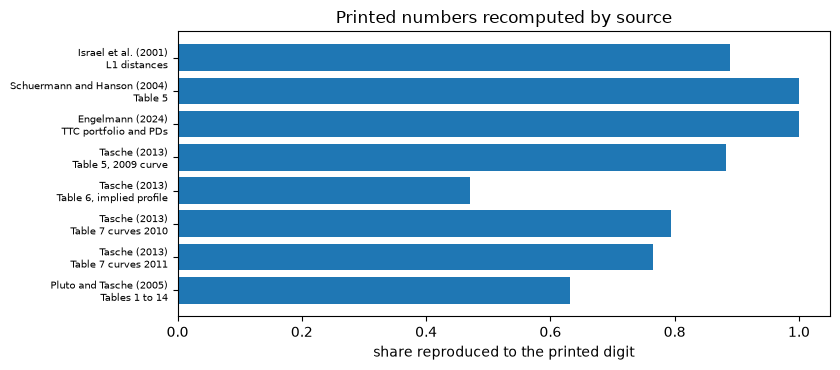

In [7]:
# Draw the share of printed numbers reproduced to the printed digit, by source
fig, ax = plt.subplots(figsize=(8.5, 3.8))
labels = [r[0].replace(", ", "\n", 1) for r in rows]
shares = [r[2] / r[1] for r in rows]
ax.barh(range(len(rows)), shares, color="tab:blue")
ax.set_yticks(range(len(rows)))
ax.set_yticklabels(labels, fontsize=7)
ax.invert_yaxis()
ax.set_xlim(0, 1.05)
ax.set_xlabel("share reproduced to the printed digit")
ax.set_title("Printed numbers recomputed by source")
fig.tight_layout()
plt.show()

## Results

- **What exists.** The ratings and calibration cases recompute 413 printed numbers of five papers beside their prints, and the engine reproduces 296 of them to the printed digit. By source: Israel et al., 8 of 9 distances (largest gap 0.0004 in the L1 distance); Schuermann and Hanson's Table 5, 18 of 18 values (all six rows agree under the rule of half a unit of the last digit); Engelmann, 12 of 12 numbers (a fourth portfolio is checked within the rounding of its printed entries and is not in the count); Tasche's Table 5, 15 of 17 (largest gap 0.0010 points), Table 6, 8 of 17 (0.0013) and Table 7 curves, 54 of 68 in 2010 and 52 of 68 in 2011 (largest 0.0005 and 0.0004 points); Pluto and Tasche, 129 of 204 (largest 0.10 points).
- **The gaps are recorded and explained.** The one Israel et al. distance that disagrees prints 0.1169 where the matrix gives 0.1165, and equals 0.1169 from the paper's printed generator. Tasche's printed p-values (4.6, 8.0, 4.0 and 11.3% in 2010; 78.5, 89.4, 36.6 and 82.2% in 2011) lie within 0.36 points of the artifact's, from 100,000 draws against the paper's 2,000. Of the 204 Pluto and Tasche cells, 60 differ by one unit of the last digit and 15 by more (0.02 to 0.10 points), listed above: Table 11 at 75% and 95%, Table 12 for B at 99.9% and the multi-period Tables 13 and 14, whose print is above the engine's Monte Carlo.
- **SciPy.** On a grid of 36 cases the engine's Jeffreys p-values equal SciPy's Beta distribution function and its binomial p-values SciPy's binomial survival function, 72 of 72 with a difference of 0.
- **Not run, so not claimed.** The Hull-White swap against ORE and the equality of the cohort estimator with `transitionMatrix`.
- **The claim.** The five statements of BS-2 are listed with the values read in this notebook.

What this notebook does not show: the reconciliations of the other cases (the notebooks of their topics name their references).

## Summary

- The ratings and calibration cases hold the engine to five printed papers and to SciPy, and report every gap: 296 of 413 printed numbers to the printed digit, the rest with their cell and their explanation.
- A gap that is explained is still listed; where a paper's arithmetic differs from its text the engine follows the text.
- Two reconciliations are not run (ORE and `transitionMatrix`) and nothing is claimed about them.
- The claim BS-2 counts what exists; it does not say that every number of the engine is reconciled.

**What to try next.** Recompute one table of Pluto and Tasche with another confidence level and compare it with the print; then read the notebooks of the next topic.

## References

- Israel, R. B., Rosenthal, J. S. and Wei, J. Z. (2001), Finding generators for Markov chains via empirical transition matrices, with applications to credit ratings, Mathematical Finance 11(2). https://doi.org/10.1111/1467-9965.00114
- Schuermann, T. and Hanson, S. (2004), Estimating probabilities of default, FRBNY Staff Report 190, Table 5. https://www.newyorkfed.org/medialibrary/media/research/staff_reports/sr190.pdf
- Tasche, D. (2013), The art of probability-of-default curve calibration, Journal of Credit Risk 9(4), Tables 5 to 9. https://doi.org/10.21314/jcr.2013.169
- Pluto, K. and Tasche, D. (2005), Estimating probabilities of default for low default portfolios, arXiv cond-mat/0411699, Tables 1 to 14. https://arxiv.org/abs/cond-mat/0411699
- Engelmann, B. (2024), Spurious default probability projections in credit risk stress testing models, arXiv 2401.08892, section 4.
- SciPy, the `scipy.stats` Beta and binomial distributions, at the pinned version of notebooks/requirements.txt.